> # 🔑 SOLUCIÓN DEL PROFESOR
> Notebook ejecutado de principio a fin. Las líneas marcadas con ✏️ son las que el alumno debe completar.
> Después de cada pregunta ✍️ hay una **respuesta modelo** y su **rúbrica**. Al final está la **hoja de respuestas rápida** de todos los huecos.

# Segundo examen parcial · Riesgo de mortalidad en cáncer de mama con cinco clasificadores
### Regresión logística · Naïve Bayes · SVM · Árbol de decisión · Random Forest

**FP13 · Inteligencia Artificial** — Universidad Autónoma de Guadalajara · **Lunes 19 de octubre de 2026** · Duración: **2 horas**

**Nombre:** ______________________________ **Matrícula:** ______________

**Unidad 4:** 4.4 Codificación one-hot · 4.6 Escalamiento
**Unidad 5:** 5.1 Clasificación · 5.3 Preprocesamiento · 5.4 Codificación de etiquetas · 5.5 Regresión logística · 5.6 Naïve Bayes · 5.7 Matrices de confusión · 5.8 SVM
**Unidad 6:** 6.1 Árboles de decisión · 6.3 Bosques aleatorios · 6.4 Clases no balanceadas · 6.5 Búsqueda de rejilla

---

### 🏥 El problema clínico
Una paciente con **cáncer de mama infiltrante** acaba de ser operada y el servicio de patología ya reportó la **estadificación** del tumor: su tamaño (**T**), cuántos ganglios tienen cáncer (**N**), el estadio, qué tan diferenciadas están las células y si el tumor tiene receptores de **estrógeno** y **progesterona**.

El servicio de oncología quiere una herramienta de **apoyo** que, con esa información, señale a las pacientes con **alto riesgo de fallecer** durante el seguimiento, para incluirlas en un **programa de vigilancia intensiva** (consultas más frecuentes, estudios de imagen y valoración de un tratamiento adyuvante más agresivo).

> ⚠️ Un **falso negativo** (decir *bajo riesgo* a una paciente que en realidad fallecerá) significa que esa paciente recibe solo el seguimiento estándar y una recaída puede detectarse demasiado tarde. Por eso, igual que en la tarea, **la exactitud no basta**: buscaremos los modelos que **dejen escapar al menor número posible de pacientes de alto riesgo**.

### 📋 Instrucciones
1. Trabaja en tu entorno de GitHub (VS Code) y ejecuta las celdas **en orden**, de arriba hacia abajo.
2. Cada `____` es un hueco que debes completar. Las líneas con huecos están marcadas con ✏️. **No modifiques el resto del código.**
3. Si una celda marca error, revisa los huecos de esa celda y de las anteriores.
4. Responde las preguntas marcadas con ✍️ (al final de la sección 3 y en la sección 11).
5. Al terminar, guarda el notebook **ejecutado** (con todos los resultados visibles) y entrégalo según las indicaciones del profesor.

### 🧮 Puntuación
| Sección | Puntos |
|---|:---:|
| 1–2 · Carga y exploración | 8 |
| 3 · Preprocesamiento: numéricas ≠ categóricas | 15 |
| 4–8 · Cinco modelos con búsqueda de rejilla (7 c/u) | 35 |
| 9–10 · Comparación final y ajuste del umbral | 12 |
| 11 · Reflexión: ¿cuál es el mejor modelo? | 30 |
| **Total** | **100** |

### ¿Qué cambia respecto a la tarea?
- Los datos son **mixtos**: 4 variables **numéricas** y 9 variables **categóricas de texto**. Cada tipo se preprocesa **de forma distinta** (temas 4.4, 4.6 y 5.3), igual que en la práctica de clase:
  - **Categóricas → one-hot** con `pd.get_dummies` (cada categoría se vuelve una columna de 0 y 1).
  - **Numéricas → `StandardScaler`**, aplicado **solo a esas columnas** con un **`ColumnTransformer`**.
- En los Pipelines de regresión logística, Naïve Bayes y SVM, el paso `("escalar", StandardScaler())` se sustituye por **`("prep", preprocesador)`**.
- Hay una columna que **"hace trampa"** (fuga de información) y otra que está **repetida**: hay que eliminarlas.
- Todo lo demás —los 5 modelos, sus rejillas, las 3 métricas, la comparación final y el ajuste del umbral— es **igual que en la tarea**.

---
## 0 · Librerías

In [1]:
# Importando librerías
import warnings
warnings.filterwarnings("ignore")      # oculta avisos técnicos para que la pantalla quede limpia

import numpy as np                     # cálculo numérico
import pandas as pd                    # tablas de datos
import matplotlib.pyplot as plt        # gráficas

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer          # NUEVO: preprocesar columnas de forma distinta
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

---
## 1 · Los datos  *(2 puntos)*

**SEER Breast Cancer** — Programa SEER (*Surveillance, Epidemiology, and End Results*) del National Cancer Institute de EE. UU., publicado en Kaggle como `reihanenamdari/breast-cancer`. El archivo dentro del dataset se llama **`Breast_Cancer.csv`**.

4,024 pacientes con cáncer de mama infiltrante (ductal y lobulillar) diagnosticadas entre 2006 y 2010.

| Tipo | Variable | ¿Qué describe? |
|---|---|---|
| 🔢 Numérica | `Age` | Edad al diagnóstico (años) |
| 🔢 Numérica | `Tumor Size` | Tamaño del tumor (mm) |
| 🔢 Numérica | `Regional Node Examined` | Ganglios linfáticos de la región que se examinaron |
| 🔢 Numérica | `Reginol Node Positive` | Ganglios que **sí tenían cáncer** (así viene escrito en el archivo, con error de dedo) |
| 🔤 Categórica | `T Stage` | T1 a T4: tamaño y extensión del tumor primario |
| 🔤 Categórica | `N Stage` | N1 a N3: qué tanto se extendió a los ganglios |
| 🔤 Categórica | `6th Stage` | Estadio clínico (IIA, IIB, IIIA, IIIB, IIIC) |
| 🔤 Categórica | `A Stage` | `Regional` o `Distant` (con metástasis a distancia) |
| 🔤 Categórica | `differentiate` y `Grade` | Grado de diferenciación de las células tumorales |
| 🔤 Categórica | `Estrogen Status`, `Progesterone Status` | Receptores hormonales: `Positive` / `Negative` |
| 🔤 Categórica | `Race`, `Marital Status` | Datos sociodemográficos |
| ⏱️ | `Survival Months` | Meses que se siguió a la paciente (hasta su fallecimiento o el cierre del estudio) |

La columna **`Status`** es lo que queremos predecir: **`Alive`** = viva al terminar el seguimiento, **`Dead`** = falleció durante el seguimiento.

In [2]:
# Importando datos desde Kaggle
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,
                            "reihanenamdari/breast-cancer",
                            "Breast_Cancer.csv")

In [3]:
# Explorando las primeras filas
df.head()    # ✏️

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [4]:
# Imprimiendo renglones y columnas del dataframe
df.shape

(4024, 16)

---
## 2 · Exploración  *(6 puntos)*

In [5]:
# Comprobando si existen datos nulos
df.isnull().sum()    # ✏️

Age                       0
Race                      0
Marital Status            0
T Stage                   0
N Stage                   0
6th Stage                 0
differentiate             0
Grade                     0
A Stage                   0
Tumor Size                0
Estrogen Status           0
Progesterone Status       0
Regional Node Examined    0
Reginol Node Positive     0
Survival Months           0
Status                    0
dtype: int64

No hay datos faltantes ✅. Pero observa bien los nombres: la columna **`'T Stage '`** trae un **espacio de más** al final. Si escribes `df['T Stage']` (sin el espacio) obtendrás un error. Lo corregiremos en la sección 3.

In [6]:
# ¿De qué tipo es cada columna?
df.dtypes    # ✏️

Age                       int64
Race                        str
Marital Status              str
T Stage                     str
N Stage                     str
6th Stage                   str
differentiate               str
Grade                       str
A Stage                     str
Tumor Size                int64
Estrogen Status             str
Progesterone Status         str
Regional Node Examined    int64
Reginol Node Positive     int64
Survival Months           int64
Status                      str
dtype: object

Las columnas de tipo **`int64`** son **numéricas**. Las de tipo **`object`** (o `str`, según tu versión de pandas) son **texto**: son las **categóricas**. Los modelos de scikit-learn **no aceptan texto**, así que esas columnas necesitarán un tratamiento diferente.

In [7]:
# Proporción de pacientes vivas y fallecidas
df['Status'].value_counts(normalize=True)    # ✏️

Status
Alive    0.846918
Dead     0.153082
Name: proportion, dtype: float64

In [8]:
# ¿differentiate y Grade dicen lo mismo?
pd.crosstab(df['differentiate'], df['Grade'])

Grade,anaplastic; Grade IV,1,2,3
differentiate,,,,
Moderately differentiated,0,0,2351,0
Poorly differentiated,0,0,0,1111
Undifferentiated,19,0,0,0
Well differentiated,0,543,0,0


Cada nivel de `differentiate` corresponde a **un solo** valor de `Grade` (por ejemplo, *Moderately differentiated* siempre es grado 2). Son **la misma información escrita dos veces** → conservaremos `differentiate` y eliminaremos **`Grade`**.

In [9]:
# Meses de seguimiento según el desenlace
df.groupby('Status')['Survival Months'].median()

Status
Alive    77.0
Dead     44.0
Name: Survival Months, dtype: float64

🚨 **Fuga de información.** `Survival Months` se conoce **hasta que termina el seguimiento** (o hasta que la paciente fallece). En el momento del diagnóstico —que es cuando usaríamos el modelo— **ese dato todavía no existe**. Además, delata la respuesta: las pacientes que fallecieron tienen muchos menos meses de seguimiento. Si la dejamos, el modelo "haría trampa" y en la vida real no serviría → la **eliminaremos**.

In [10]:
# Comparando la escala de las variables numéricas
df[['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive']].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4024.0,53.972167,8.963134,30.0,47.0,54.0,61.0,69.0
Tumor Size,4024.0,30.473658,21.119696,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,4024.0,14.357107,8.099675,1.0,9.0,14.0,19.0,61.0
Reginol Node Positive,4024.0,4.158052,5.109331,1.0,1.0,2.0,5.0,46.0


`Tumor Size` llega a **140** mientras que `Reginol Node Positive` suele estar entre **1 y 5**: las numéricas están en escalas muy distintas → necesitan **`StandardScaler`** para la regresión logística y la SVM. En cambio, las columnas que saldrán del one-hot ya valen **0 o 1**: no hace falta escalarlas.

---
## 3 · Preprocesamiento: numéricas y categóricas por separado  *(15 puntos)*

1. **Limpiar** los nombres de las columnas y **eliminar** las que no deben usarse (`Survival Months` y `Grade`).
2. **Codificar la etiqueta** `Status` con `LabelEncoder`.
3. **Separar** `X` de `y`.
4. **Identificar** qué columnas de `X` son numéricas y cuáles son categóricas.
5. **Categóricas → one-hot** con `pd.get_dummies`.
6. **Dividir** en entrenamiento y prueba conservando la proporción de fallecidas (`stratify`).
7. **Numéricas → `StandardScaler`**, dentro de un **`ColumnTransformer`** que deje pasar sin cambios las columnas del one-hot.

In [11]:
# Quitando espacios sobrantes en los nombres de las columnas ('T Stage ' → 'T Stage')
df.columns = df.columns.str.strip()    # ✏️

# Eliminando la columna con fuga de información y la columna repetida
df = df.drop(columns=['Survival Months', 'Grade'])    # ✏️
df.shape

(4024, 14)

In [12]:
# Codificando la etiqueta: texto → número
codificador = LabelEncoder()
df['Status'] = codificador.fit_transform(df['Status'])    # ✏️

# ¿Qué número recibió cada texto?
print(codificador.classes_)          # posición 0 → primer texto, posición 1 → segundo texto
df['Status'].value_counts()

['Alive' 'Dead']


Status
0    3408
1     616
Name: count, dtype: int64

`LabelEncoder` asigna los números en **orden alfabético**: **Alive → 0** y **Dead → 1**. La clase **positiva (1)** es la que queremos detectar: **paciente que fallece (alto riesgo)**. Así, `recall` medirá *"de cada 100 pacientes que fallecieron, ¿a cuántas detectó el modelo como alto riesgo?"*.

In [13]:
# Separando X (características) de y (desenlace)
y = df['Status']    # ✏️
X = df.drop(columns=['Status'])

print(X.shape, y.shape)

(4024, 13) (4024,)


In [14]:
# Identificando qué columnas son numéricas y cuáles son categóricas (texto)
columnas_numericas   = X.select_dtypes(include='number').columns.tolist()    # ✏️
columnas_categoricas = X.select_dtypes(exclude='number').columns.tolist()

print('Numéricas:  ', columnas_numericas)
print('Categóricas:', columnas_categoricas)

Numéricas:   ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive']
Categóricas: ['Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'differentiate', 'A Stage', 'Estrogen Status', 'Progesterone Status']


In [15]:
# One-hot SOLO a las categóricas: cada categoría se vuelve una columna de 0 y 1
X = pd.get_dummies(X, columns=columnas_categoricas, drop_first=True, dtype=int)    # ✏️

print(X.shape)
X.head()

(4024, 25)


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive,Race_Other,Race_White,Marital Status_Married,Marital Status_Separated,Marital Status_Single,Marital Status_Widowed,...,6th Stage_IIB,6th Stage_IIIA,6th Stage_IIIB,6th Stage_IIIC,differentiate_Poorly differentiated,differentiate_Undifferentiated,differentiate_Well differentiated,A Stage_Regional,Estrogen Status_Positive,Progesterone Status_Positive
0,68,4,24,1,0,1,1,0,0,0,...,0,0,0,0,1,0,0,1,1,1
1,50,35,14,5,0,1,1,0,0,0,...,0,1,0,0,0,0,0,1,1,1
2,58,63,14,7,0,1,0,0,0,0,...,0,0,0,1,0,0,0,1,1,1
3,58,18,2,1,0,1,1,0,0,0,...,0,0,0,0,1,0,0,1,1,1
4,47,41,3,1,0,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,1


Pasamos de **13** a **25** columnas: las 4 numéricas quedan igual y las 9 categóricas se convierten en 21 columnas de 0/1.

`drop_first=True` elimina **una** categoría de cada variable (la primera en orden alfabético, que queda como *referencia*) porque es redundante: si una paciente **no** es `T2`, ni `T3`, ni `T4`, entonces es `T1`.

In [16]:
# Dividiendo en entrenamiento (80 %) y prueba (20 %), conservando la proporción viva/fallecida
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,
                                                    stratify=y, random_state=42)    # ✏️

print(f'Dimensiones de entrenamiento:          {X_train.shape}')
print(f'Dimensiones de prueba:                 {X_test.shape}')
print(f'Pacientes que fallecieron en prueba:   {y_test.sum()}')

Dimensiones de entrenamiento:          (3219, 25)
Dimensiones de prueba:                 (805, 25)
Pacientes que fallecieron en prueba:   123


In [17]:
# Preprocesador: escala SOLO las numéricas; las columnas 0/1 del one-hot pasan sin cambios
preprocesador = ColumnTransformer(
    transformers=[("num", StandardScaler(), columnas_numericas)],    # ✏️
    remainder="passthrough",                  # ¿qué hacer con las columnas que no están en la lista?  ✏️
    verbose_feature_names_out=False
)

# Comprobación: ajustamos con entrenamiento y revisamos media, desviación, mínimo y máximo
X_train_prep = preprocesador.fit_transform(X_train)
resumen = pd.DataFrame(X_train_prep, columns=preprocesador.get_feature_names_out())
resumen.describe().T[['mean', 'std', 'min', 'max']].round(2).head(8)

,mean,std,min,max
Age,0.00,1.00,-2.66,1.68
Tumor Size,0.00,1.00,-1.40,5.22
Regional Node Examined,-0.00,1.00,-1.65,5.80
Reginol Node Positive,-0.00,1.00,-0.61,8.20
Race_Other,0.08,0.27,0.00,1.00
Race_White,0.85,0.36,0.00,1.00
Marital Status_Married,0.66,0.47,0.00,1.00
Marital Status_Separated,0.01,0.11,0.00,1.00


Las 4 numéricas quedaron con **media 0 y desviación 1**; las columnas del one-hot siguen valiendo **0 o 1**.

> ⚠️ Por defecto, `ColumnTransformer` usa `remainder="drop"`: **tira** todas las columnas que no le indicaste. Sin `"passthrough"` el modelo se quedaría solo con las 4 numéricas y perdería toda la información de estadificación.

Este `preprocesador` será el **primer paso** de los Pipelines de regresión logística, Naïve Bayes y SVM. Dentro de `GridSearchCV` se vuelve a ajustar en cada pliegue usando **solo** los datos de entrenamiento de ese pliegue.

**Pregunta rápida · Preprocesamiento** *(3 pts)*
Explica con tus palabras: **(a)** ¿por qué no basta con convertir cada categoría de una variable como `Marital Status` en un número 0, 1, 2, 3…? **(b)** ¿Por qué escalamos las numéricas pero **no** las columnas del one-hot? **(c)** ¿Por qué los árboles **sí** necesitan el one-hot pero **no** el escalamiento?

✅ **Respuesta modelo:**

**(a)** Si codificamos `Married = 1`, `Separated = 2`, `Single = 3`, `Widowed = 4`, el modelo interpreta un **orden y unas distancias que no existen** ("viuda" valdría 4 veces "casada" y "separada" quedaría "a la mitad" entre las dos). La regresión logística y la SVM usan esos números en sumas y distancias, así que el resultado dependería de un orden arbitrario. El one-hot crea una columna 0/1 por categoría y **no inventa ningún orden**. *(Matiz aceptable: en variables ordinales como `T Stage` sí existe un orden, pero las distancias entre T1–T2 y T3–T4 no son iguales; el one-hot es la opción segura.)*

**(b)** Las numéricas tienen escalas muy distintas (`Tumor Size` hasta 140 mm vs. ganglios positivos casi siempre < 10); sin escalar, la variable de mayor rango dominaría las distancias de la SVM y la regularización de la regresión logística. Las dummies ya están en una escala común y fácil de interpretar (0 = no, 1 = sí); escalarlas no aporta y hace que dejen de leerse como "sí/no".

**(c)** scikit-learn **no acepta texto** como entrada: cualquier modelo, incluidos los árboles, necesita números → one-hot. Pero un árbol solo hace preguntas del tipo *"¿`Tumor Size` ≤ 32?"*: el orden de los valores no cambia al escalar, así que la división es la misma → el escalamiento no le afecta.

**Rúbrica (3 pts):** 1 pt por inciso. (a) debe mencionar el orden/distancia artificial; (b) escalas distintas en numéricas **y** que las dummies ya son 0/1; (c) "no acepta texto" **y** "las preguntas de umbral no dependen de la escala". Medio punto si la idea es correcta pero incompleta.

---
## 4 · ¿Cómo vamos a evaluar?

Las filas son la **realidad** y las columnas lo que **predice** el modelo:

| | Predice **Viva** (bajo riesgo) | Predice **Fallece** (alto riesgo) |
|---|:---:|:---:|
| **Realmente viva** | ✅ VN · seguimiento estándar, correcto | ⚠️ FP · vigilancia intensiva de más (consultas y estudios extra) |
| **Realmente falleció** | ❌ **FN · paciente de alto riesgo sin vigilancia intensiva** | ✅ VP · paciente de alto riesgo detectada |

<br>

| Métrica | Pregunta clínica que responde |
|---|---|
| **Exactitud** (`accuracy`) | De cada 100 pacientes, ¿cuántas clasifica bien? |
| **Precisión** (`precision`) | Cuando dice "alto riesgo", ¿cuántas veces acierta? |
| **Sensibilidad** (`recall`) | De cada 100 pacientes que fallecieron, ¿a cuántas detectó? |
| **Especificidad** | De cada 100 pacientes que siguen vivas, ¿a cuántas descartó bien? |

**Regla de este examen (igual que en la tarea):** cada modelo se optimiza con 3 métricas distintas (`accuracy`, `precision` y `recall`). De esas 3 versiones, guardaremos como **finalista** la optimizada con **`recall`** (sensibilidad), porque es la que busca dejar escapar el menor número de pacientes de alto riesgo (FN).

In [18]:
# Nombres de las clases (0 y 1 respectivamente)
clases = ['Viva', 'Fallece']

# Métricas con las que vamos a optimizar cada modelo
metricas = ['accuracy', 'precision', 'recall']

# Aquí guardaremos el modelo finalista de cada algoritmo
finalistas = {}

---
## 5 · Regresión logística  *(7 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`C`** | Inverso de la regularización: `C` pequeño = modelo más simple y "prudente" | 0.01 · 0.1 · 1 · 10 · 100 |
| **`l1_ratio`** | Tipo de regularización: 0 = L2 · 1 = L1 (puede apagar variables) · 0.5 = mezcla | 0 · 0.5 · 1 |
| **`class_weight`** | `"balanced"` le da más peso a la clase con menos pacientes (las que fallecen) | `None` · `"balanced"` |

In [19]:
# Importando el modelo
from sklearn.linear_model import LogisticRegression

# Pipeline: preprocesar (escalar numéricas, pasar dummies) → modelo
reglog_base = Pipeline([
    ("prep",   preprocesador),    # ✏️
    ("modelo", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0,    # ✏️
                                  max_iter=5000, random_state=42))
])

# Ajustando el modelo con valores por defecto
reglog_base.fit(X_train, y_train)    # ✏️

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['Age','Tumor Size','Regional Node Examined',...,'A Stage_Regional', 'Estrogen Status_Positive','Progesterone Status_Positive']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

              precision    recall  f1-score   support

        Viva       0.87      0.99      0.92       682
     Fallece       0.67      0.15      0.24       123

    accuracy                           0.86       805
   macro avg       0.77      0.57      0.58       805
weighted avg       0.83      0.86      0.82       805



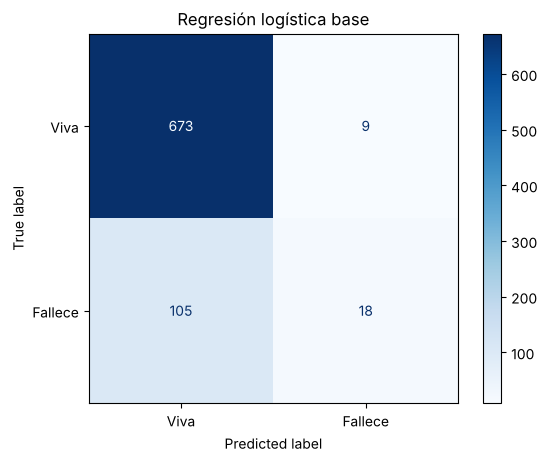

In [20]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = reglog_base.predict(X_test)    # ✏️

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Regresión logística base')
plt.show()

In [21]:
# Hiperparámetros a optimizar
rejilla_reglog = {
    "modelo__C":            [0.01, 0.1, 1, 10, 100],
    "modelo__l1_ratio":     [0, 0.5, 1],             # 0 = L2 · 0.5 = mezcla · 1 = L1  ✏️
    "modelo__class_weight": [None, "balanced"],    # ✏️
}
# 5 × 3 × 2 = 30 combinaciones

In [22]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(reglog_base, rejilla_reglog, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_    # ✏️
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.856  {'modelo__C': 10, 'modelo__class_weight': None, 'modelo__l1_ratio': 0}


precision >> 0.684  {'modelo__C': 0.01, 'modelo__class_weight': None, 'modelo__l1_ratio': 0}


recall >> 0.643  {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 0}


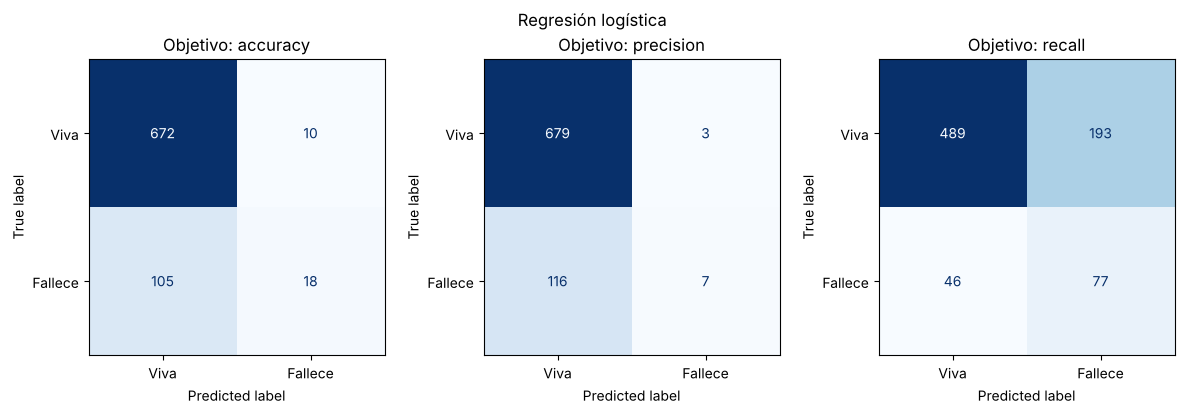

In [23]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))      # 1 fila con 3 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Regresión logística')
plt.tight_layout()
plt.show()

In [24]:
# Guardando como finalista la versión optimizada con recall
finalistas['Regresión logística'] = mejores_modelos['recall']    # ✏️

---
## 6 · Naïve Bayes  *(7 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`var_smoothing`** | Suma una pequeña cantidad a las varianzas para que ninguna sea casi cero. Valores grandes = modelo más "suavizado" | 10 valores entre 10⁻⁹ y 1, generados con `np.logspace(-9, 0, 10)` |
| **`priors`** | Probabilidad inicial que el modelo asume para cada clase, en el orden `[viva, fallece]`. `None` = la proporción de los datos | `None` · `[0.5, 0.5]` · `[0.3, 0.7]` |

In [25]:
# Importando el modelo
from sklearn.naive_bayes import GaussianNB

# Pipeline: preprocesar → modelo
nb_base = Pipeline([
    ("prep",   preprocesador),
    ("modelo", GaussianNB())    # ✏️
])

# Ajustando el modelo con valores por defecto
nb_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['Age','Tumor Size','Regional Node Examined',...,'A Stage_Regional', 'Estrogen Status_Positive','Progesterone Status_Positive']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

              precision    recall  f1-score   support

        Viva       0.89      0.84      0.86       682
     Fallece       0.32      0.41      0.36       123

    accuracy                           0.78       805
   macro avg       0.60      0.63      0.61       805
weighted avg       0.80      0.78      0.79       805



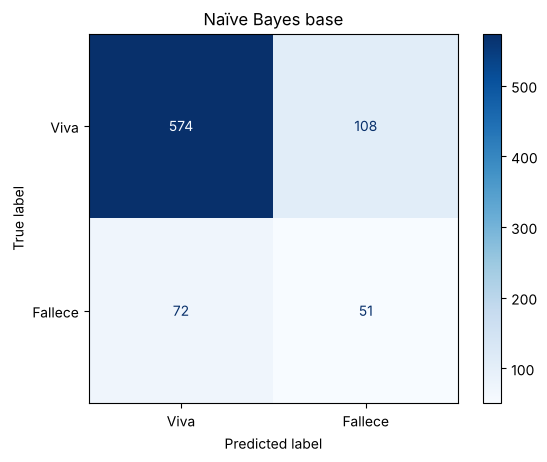

In [26]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = nb_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))    # ✏️

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Naïve Bayes base')
plt.show()

In [27]:
# Hiperparámetros a optimizar
rejilla_nb = {
    "modelo__var_smoothing": np.logspace(-9, 0, 10),               # 10 valores: 1e-9, 1e-8, …, 1  ✏️
    "modelo__priors":        [None, [0.5, 0.5], [0.3, 0.7]],        # [viva, fallece]  ✏️
}
# 10 × 3 = 30 combinaciones

In [28]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(nb_base, rejilla_nb, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.847  {'modelo__priors': None, 'modelo__var_smoothing': np.float64(1.0)}


precision >> 0.516  {'modelo__priors': None, 'modelo__var_smoothing': np.float64(1.0)}


recall >> 0.653  {'modelo__priors': [0.3, 0.7], 'modelo__var_smoothing': np.float64(1.0)}


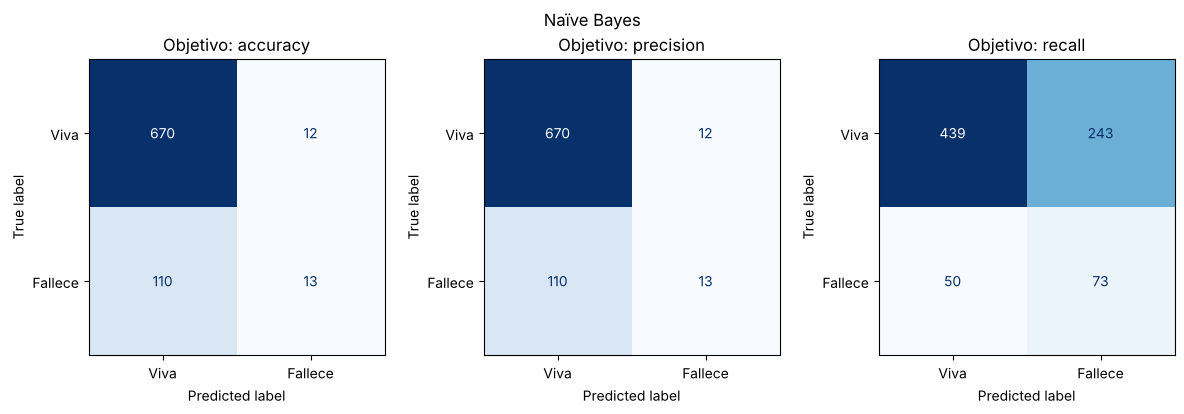

In [29]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Naïve Bayes')
plt.tight_layout()
plt.show()

In [30]:
# Guardando como finalista la versión optimizada con recall
finalistas['Naïve Bayes'] = mejores_modelos['recall']

---
## 7 · Máquinas de vectores de soporte (SVM)  *(7 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`kernel`** | La forma de la frontera: `"linear"` = recta · `"rbf"` = curvas suaves · `"poly"` = curva polinomial | los tres |
| **`C`** | Qué tanto castiga los errores en entrenamiento: `C` grande = frontera más ajustada (riesgo de sobreajuste) | 0.01 · 0.1 · 1 · 10 · 100 |
| **`gamma`** *(solo rbf)* | Qué tan "local" es la influencia de cada paciente | `"scale"` · 0.01 · 0.1 |
| **`degree`** *(solo poly)* | Grado del polinomio: 2 = parábola, 3 = cúbica | 2 · 3 |
| **`class_weight`** | `"balanced"` da más peso a las pacientes que fallecen | `None` · `"balanced"` |

Como cada kernel usa hiperparámetros distintos, la rejilla es una **lista de diccionarios** (uno por kernel).

⏱️ Con 4,000 pacientes esta búsqueda tarda **varios minutos**. Mientras corre, puedes avanzar leyendo las secciones siguientes.

> 🆕 **`max_iter=1_000_000`** es un **tope de iteraciones**, no un hiperparámetro que vayamos a optimizar. Con estos datos, la combinación `kernel="linear"` + `C=100` tarda **~5 minutos por pliegue** en converger (los datos se traslapan mucho y la SVM "pelea" por acomodar cada punto). El tope la detiene a tiempo para que la búsqueda completa tarde minutos y no media hora. Si aparece un aviso `ConvergenceWarning`, es normal: corresponde a esa combinación.

In [31]:
# Importando el modelo
from sklearn.svm import SVC

# Pipeline: preprocesar → modelo
svm_base = Pipeline([
    ("prep",   preprocesador),
    ("modelo", SVC(max_iter=1_000_000))    # tope de iteraciones (ver nota arriba)  ✏️
])

# Ajustando el modelo con valores por defecto
svm_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['Age','Tumor Size','Regional Node Examined',...,'A Stage_Regional', 'Estrogen Status_Positive','Progesterone Status_Positive']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

              precision    recall  f1-score   support

        Viva       0.86      1.00      0.92       682
     Fallece       0.73      0.07      0.12       123

    accuracy                           0.85       805
   macro avg       0.79      0.53      0.52       805
weighted avg       0.84      0.85      0.80       805



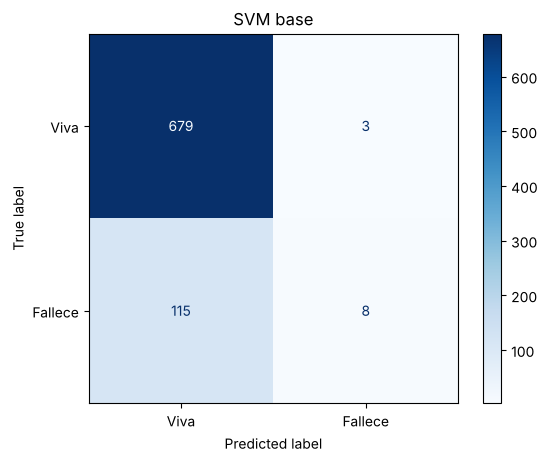

In [32]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = svm_base.predict(X_test)    # ✏️

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('SVM base')
plt.show()

In [33]:
# Hiperparámetros a optimizar
valores_C = [0.01, 0.1, 1, 10, 100]

rejilla_svm = [
    {"modelo__kernel":       ["linear"],
     "modelo__C":            valores_C,
     "modelo__class_weight": [None, "balanced"]},

    {"modelo__kernel":       ["rbf"],    # ✏️
     "modelo__C":            valores_C,
     "modelo__gamma":        ["scale", 0.01, 0.1],
     "modelo__class_weight": [None, "balanced"]},

    {"modelo__kernel":       ["poly"],
     "modelo__C":            valores_C,
     "modelo__degree":     [2, 3],                      # grado del polinomio  ✏️
     "modelo__class_weight": [None, "balanced"]},
]
# 10 + 30 + 20 = 60 combinaciones

In [34]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(svm_base, rejilla_svm, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.853  {'modelo__C': 1, 'modelo__class_weight': None, 'modelo__degree': 3, 'modelo__kernel': 'poly'}


precision >> 0.788  {'modelo__C': 10, 'modelo__class_weight': None, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}


recall >> 0.629  {'modelo__C': 0.1, 'modelo__class_weight': 'balanced', 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}


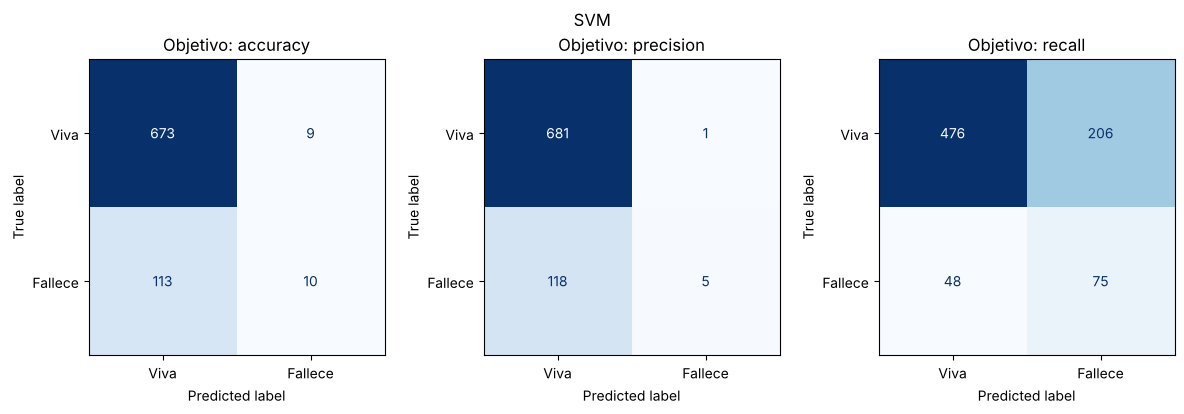

In [35]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('SVM')
plt.tight_layout()
plt.show()

In [36]:
# Guardando como finalista la versión optimizada con recall
finalistas['SVM'] = mejores_modelos['recall']

---
## 8 · Árbol de decisión y Random Forest  *(7 + 7 puntos)*

Los árboles **no necesitan escalar**: solo hacen preguntas del tipo *"¿`Tumor Size` ≤ 32?"*, y la respuesta es la misma en cualquier escala. Pero **sí necesitan el one-hot**, porque scikit-learn no acepta texto. Como el one-hot ya se aplicó a `X` en la sección 3, aquí usamos `X_train` **directamente, sin Pipeline**, y los nombres de la rejilla van **sin** el prefijo `modelo__` (igual que en la tarea).

### 8.1 Árbol de decisión

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`max_depth`** | Cuántas preguntas seguidas puede hacer (los "pisos" del árbol). `None` = sin límite | 2 · 3 · 4 · 5 · 6 · `None` |
| **`min_samples_leaf`** | Mínimo de pacientes en cada hoja | 1 · 5 · 10 |
| **`min_samples_split`** | Mínimo de pacientes que debe tener un nodo para **poder dividirse** | 2 · 10 · 20 |
| **`criterion`** | Fórmula que mide qué tan "revuelto" queda un grupo | `"gini"` · `"entropy"` |
| **`class_weight`** | `"balanced"` da más peso a las pacientes que fallecen | `None` · `"balanced"` |

In [37]:
# Importando el modelo y la función para dibujarlo
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Creando y ajustando el árbol con valores por defecto (sin Pipeline: no hace falta escalar)
arbol_base = DecisionTreeClassifier(random_state=42)    # ✏️
arbol_base.fit(X_train, y_train)

print('Pisos (profundidad):        ', arbol_base.get_depth())
print('Hojas (decisiones finales): ', arbol_base.get_n_leaves())

Pisos (profundidad):         26
Hojas (decisiones finales):  627


              precision    recall  f1-score   support

        Viva       0.86      0.83      0.85       682
     Fallece       0.22      0.27      0.24       123

    accuracy                           0.74       805
   macro avg       0.54      0.55      0.54       805
weighted avg       0.76      0.74      0.75       805



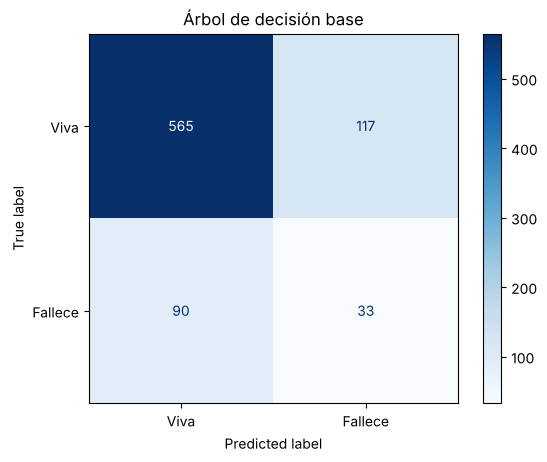

In [38]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = arbol_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')    # ✏️
plt.title('Árbol de decisión base')
plt.show()

In [39]:
# Hiperparámetros a optimizar (sin el prefijo modelo__ porque no hay Pipeline)
rejilla_arbol = {
    "max_depth":         [2, 3, 4, 5, 6, None],        # None = sin límite
    "min_samples_leaf":  [1, 5, 10],
    "min_samples_split": [2, 10, 20],    # ✏️
    "criterion":         ["gini", "entropy"],    # ✏️
    "class_weight":      [None, "balanced"],
}
# 6 × 3 × 3 × 2 × 2 = 216 combinaciones (muchas, pero cada árbol tarda milisegundos)

In [40]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(arbol_base, rejilla_arbol, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.853  {'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}


precision >> 0.579  {'class_weight': None, 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10, 'min_samples_split': 2}


recall >> 0.601  {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}


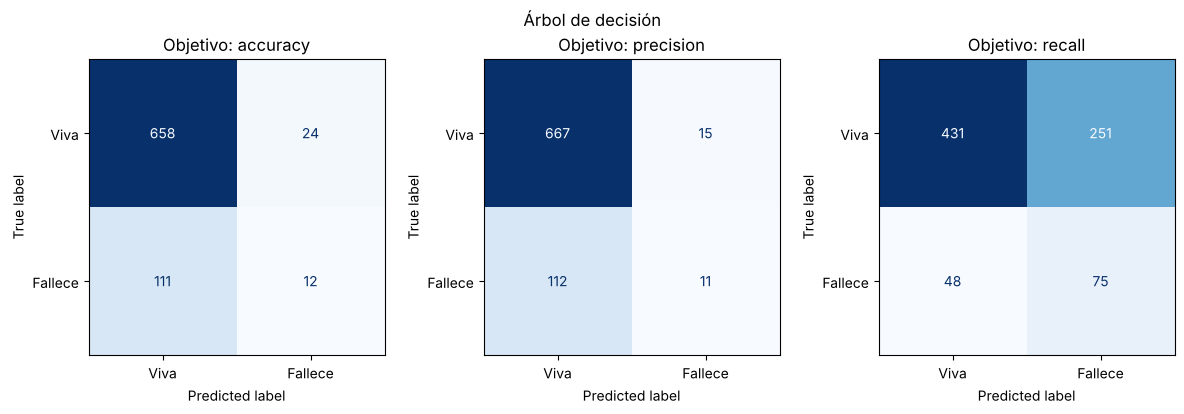

In [41]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Árbol de decisión')
plt.tight_layout()
plt.show()

In [42]:
# Guardando como finalista la versión optimizada con recall
finalistas['Árbol de decisión'] = mejores_modelos['recall']

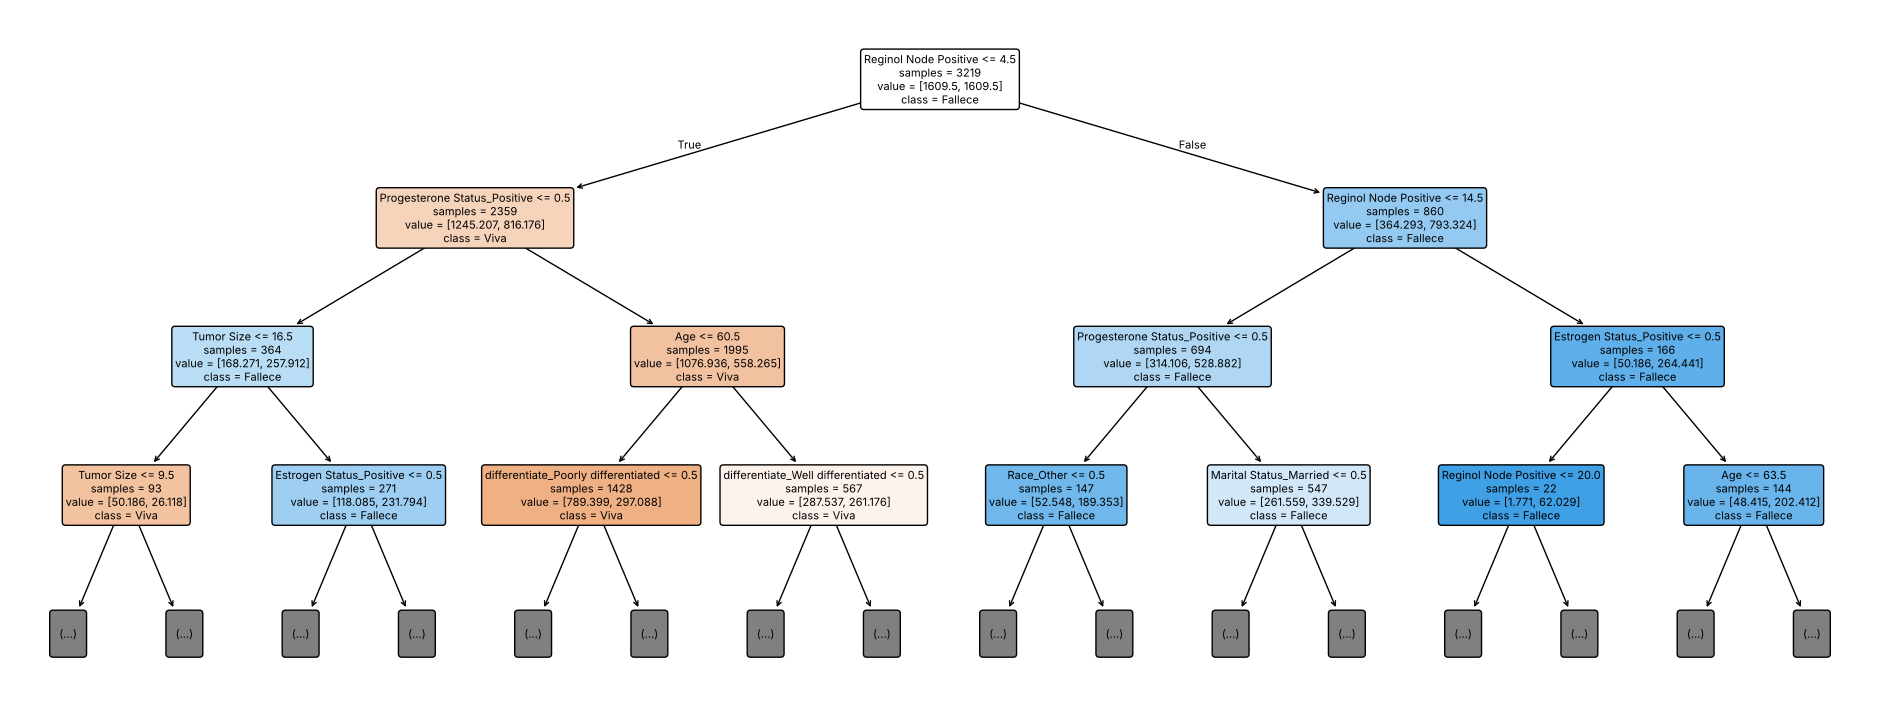

In [43]:
# Dibujando solo los primeros 3 pisos del árbol finalista (completo no cabría en pantalla)
plt.figure(figsize=(24, 9))
plot_tree(finalistas['Árbol de decisión'], feature_names=X.columns, class_names=clases,
          filled=True, rounded=True, impurity=False, max_depth=3, fontsize=8)    # ✏️
plt.show()

> Si el árbol finalista usa `class_weight="balanced"`, los números de `value` son **pacientes ponderadas** (cada paciente que fallece "vale" más que una que sigue viva), por eso no son enteros. Las cajas **azules** votan *Fallece* y las **naranjas** *Viva*; entre más intenso el color, más seguro está el árbol. Observa que las preguntas también usan las columnas del **one-hot**: por ejemplo, `Progesterone Status_Positive <= 0.5` significa *"¿el tumor **no** tiene receptores de progesterona?"*.

### 8.2 Random Forest

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`n_estimators`** | Cuántos árboles votan | 100 · 300 |
| **`max_features`** | Entre cuántas variables al azar elige cada árbol en cada pregunta. Con 25 columnas: `"sqrt"` → 5 · `"log2"` → 4 | `"sqrt"` · `"log2"` |
| **`max_depth`** | Igual que en el árbol | 5 · `None` |
| **`min_samples_leaf`** | Mínimo de pacientes en cada hoja de cada árbol | 1 · 3 |
| **`class_weight`** | `"balanced"` da más peso a las pacientes que fallecen | `None` · `"balanced"` |

⏱️ Esta búsqueda también tarda unos **minutos**: cada combinación entrena cientos de árboles. Ten paciencia.

In [44]:
# Importando el modelo
from sklearn.ensemble import RandomForestClassifier

# Creando y ajustando el bosque con valores por defecto
bosque_base = RandomForestClassifier(random_state=42)    # ✏️
bosque_base.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

              precision    recall  f1-score   support

        Viva       0.86      0.97      0.91       682
     Fallece       0.38      0.11      0.17       123

    accuracy                           0.84       805
   macro avg       0.62      0.54      0.54       805
weighted avg       0.78      0.84      0.80       805



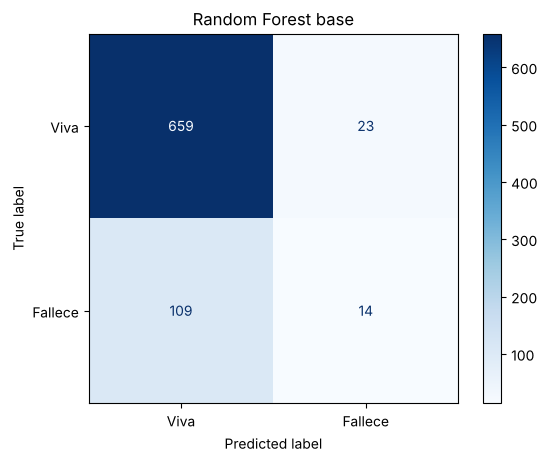

In [45]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = bosque_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))    # ✏️

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Random Forest base')
plt.show()

In [46]:
# Hiperparámetros a optimizar
rejilla_bosque = {
    "n_estimators":     [100, 300],
    "max_features":     ["sqrt", "log2"],            # 5 o 4 columnas al azar  ✏️
    "max_depth":        [5, None],
    "min_samples_leaf": [1, 3],    # ✏️
    "class_weight":     [None, "balanced"],
}
# 2 × 2 × 2 × 2 × 2 = 32 combinaciones

In [47]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(bosque_base, rejilla_bosque, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.854  {'class_weight': None, 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 3, 'n_estimators': 300}


precision >> 0.675  {'class_weight': None, 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 100}


recall >> 0.570  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 3, 'n_estimators': 100}


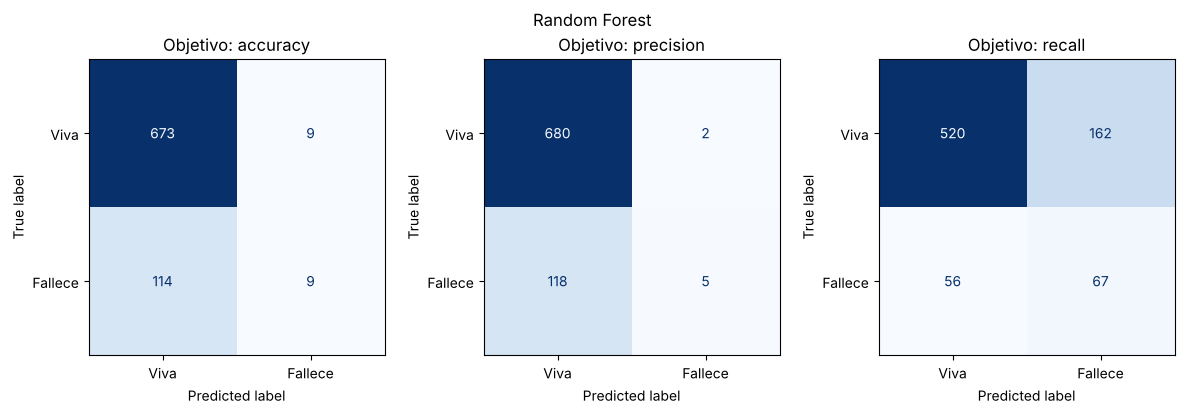

In [48]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Random Forest')
plt.tight_layout()
plt.show()

In [49]:
# Guardando como finalista la versión optimizada con recall
finalistas['Random Forest'] = mejores_modelos['recall']

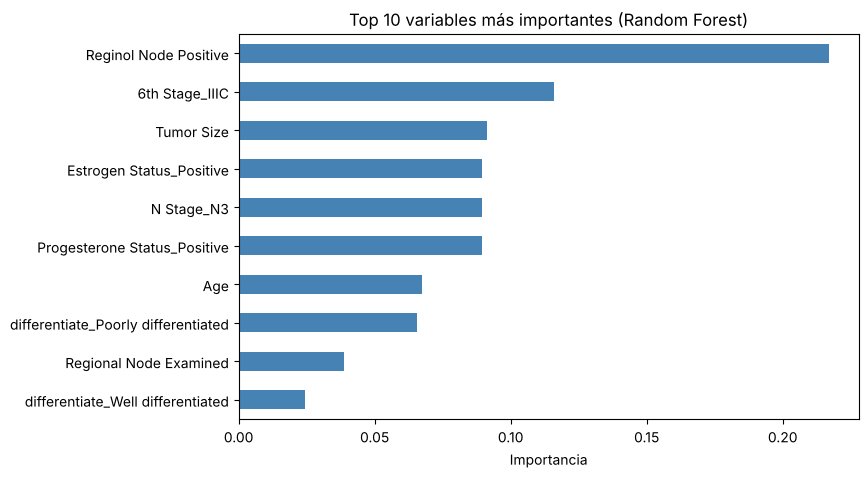

In [50]:
# ¿Qué columnas usó más el bosque para decidir?
importancias = pd.Series(finalistas['Random Forest'].feature_importances_, index=X.columns)    # ✏️

importancias.sort_values().tail(10).plot.barh(figsize=(8, 5), color='steelblue')
plt.title('Top 10 variables más importantes (Random Forest)')
plt.xlabel('Importancia')
plt.show()

---
## 9 · Comparación final de los cinco finalistas  *(6 puntos)*

Ahora comparamos los 5 finalistas **con las mismas pacientes de prueba**. Completa las fórmulas de sensibilidad y especificidad usando VP, VN, FP y FN.

La tabla queda ordenada de **menos FN a más FN** (y, si hay empate, de menos FP a más FP).

In [51]:
filas = []

for nombre, modelo in finalistas.items():
    y_pred = modelo.predict(X_test)
    vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()      # los 4 números de la matriz
    filas.append({
        'Modelo':        nombre,
        'Exactitud':     (vp + vn) / len(y_test),
        'Sensibilidad':  vp / (vp + fn),             # de las que fallecieron, ¿a cuántas detecta?  ✏️
        'Especificidad': vn / (vn + fp),             # de las que siguen vivas, ¿a cuántas descarta bien?  ✏️
        'FN':            fn,
        'FP':            fp,
    })

tabla = pd.DataFrame(filas).sort_values(by=['FN', 'FP'])
tabla.round(3)

,Modelo,Exactitud,Sensibilidad,Especificidad,FN,FP
0,Regresión logística,0.703,0.626,0.717,46,193
2,SVM,0.684,0.610,0.698,48,206
3,Árbol de decisión,0.629,0.610,0.632,48,251
1,Naïve Bayes,0.636,0.593,0.644,50,243
4,Random Forest,0.729,0.545,0.762,56,162


---
## 10 · Ajuste del umbral de decisión  *(6 puntos)*

Por defecto, los modelos dicen **"Fallece"** cuando la probabilidad de fallecer es **≥ 0.5**. Si **bajamos el umbral**, el modelo se vuelve más "desconfiado": detecta a más pacientes de alto riesgo (**menos FN**), a cambio de más falsas alarmas (**más FP**).

Lo probaremos con la **regresión logística** y el **Random Forest**, que calculan probabilidades con `predict_proba`. (La SVM no las calcula por defecto.)

In [52]:
umbrales = [0.5, 0.4, 0.3, 0.2, 0.1]

for nombre in ['Regresión logística', 'Random Forest']:
    proba = finalistas[nombre].predict_proba(X_test)[:, 1]      # columna 1 = probabilidad de "Fallece"  ✏️
    print(nombre)

    for umbral in umbrales:
        y_pred_u = (proba >= umbral).astype(int)                # 1 si supera el umbral, 0 si no  ✏️
        vn, fp, fn, vp = confusion_matrix(y_test, y_pred_u).ravel()
        print(f'   umbral {umbral}:   FN = {fn}   FP = {fp}')
    print()

Regresión logística
   umbral 0.5:   FN = 46   FP = 193
   umbral 0.4:   FN = 28   FP = 311
   umbral 0.3:   FN = 15   FP = 436
   umbral 0.2:   FN = 4   FP = 594
   umbral 0.1:   FN = 0   FP = 679

Random Forest
   umbral 0.5:   FN = 56   FP = 162
   umbral 0.4:   FN = 30   FP = 351
   umbral 0.3:   FN = 2   FP = 582
   umbral 0.2:   FN = 0   FP = 682
   umbral 0.1:   FN = 0   FP = 682



---
## 11 · Reflexión: ¿cuál es el mejor modelo?  *(30 puntos)*

Responde con tus propias palabras y **apóyate en los números** que obtuviste (matrices, tabla de la sección 9 y umbrales de la sección 10). No basta con decir "es mejor": explica **por qué**.

**Pregunta 1 · Falsos negativos vs. falsos positivos** *(7 pts)*
En este problema, ¿qué significa clínicamente un **falso negativo**? Describe qué le pasaría a esa paciente y compáralo con lo que le pasaría a una paciente con un **falso positivo**. ¿Cuál de los dos errores es más costoso y por qué?

✅ **Respuesta modelo:**

Un **falso negativo** es una paciente que **sí fallecerá** durante el seguimiento, pero el modelo la clasifica como **Viva (bajo riesgo)**. Queda en el seguimiento estándar, con consultas más espaciadas: una recaída local o una metástasis se detecta tarde, cuando hay menos opciones de tratamiento, y se pierde la oportunidad de valorar un tratamiento adyuvante más intenso. Es un error que puede ser **irreversible**.

Un **falso positivo** es una paciente que **seguirá viva**, pero el modelo la marca como **alto riesgo**. Recibe consultas y estudios de imagen de más (costo, tiempo, ansiedad, radiación de algunos estudios) y, en el peor caso, se le podría proponer un tratamiento más agresivo con efectos adversos. Es un costo real, pero en su mayoría **reversible**: las siguientes consultas lo corrigen.

Por eso el **FN es el error más costoso**: significa perder la oportunidad de actuar a tiempo en una enfermedad potencialmente mortal, mientras que el FP se traduce sobre todo en recursos y molestias. Aun así, el FP **no es gratis**: si el modelo marcara a todas como alto riesgo, el programa de vigilancia intensiva se saturaría (con la regresión logística y umbral 0.1 se marcan **679 de las 682** pacientes vivas).

**Rúbrica (7 pts)**
| Criterio | Pts |
|---|:---:|
| Define bien el FN en este contexto (realmente fallece → el modelo dice *Viva*) | 2 |
| Consecuencia clínica concreta del FN (vigilancia estándar, recaída detectada tarde, oportunidad perdida) | 1.5 |
| Define el FP y su consecuencia (estudios/consultas extra, ansiedad, costo, posible sobretratamiento) | 2 |
| Compara y justifica cuál es más costoso (irreversible vs. mayormente reversible) | 1.5 |

**Pregunta 2 · ¿Con qué métrica optimizar?** *(6 pts)*
Elige uno de los modelos y compara sus matrices de confusión con objetivo `precision` y con objetivo `recall`. ¿Qué pasó con los FN y con los FP? ¿Por qué optimizar la precisión **no** es buena idea en este contexto?

✅ **Respuesta modelo** *(ejemplo con regresión logística; cualquier modelo sirve si los números son los de su matriz)*:

| Regresión logística | FN | FP | Fallecidas detectadas (VP) |
|---|:---:|:---:|:---:|
| Objetivo `precision` | **116** | 3 | 7 de 123 |
| Objetivo `recall` | **46** | 193 | 77 de 123 |

Al optimizar `precision`, el modelo solo dice *"Fallece"* cuando está casi seguro: tiene apenas **3 falsas alarmas**, pero deja escapar a **116 de 123** pacientes de alto riesgo (94 %). Al optimizar `recall`, los FN bajan a **46** (detecta 77), a cambio de que los FP suben a **193**.

La precisión (VP / (VP + FP)) **no incluye a los FN en su fórmula**: un modelo que casi nunca dice "Fallece" puede tener muy buena precisión y, aun así, abandonar a casi todas las pacientes de alto riesgo. En este problema el error que más importa es justamente el FN, así que optimizar la precisión premia el comportamiento opuesto al que queremos.

El patrón se repite en los cinco modelos (FN / FP con `precision` → con `recall`): SVM **118 / 1 → 48 / 206** · Árbol **112 / 15 → 48 / 251** · Random Forest **118 / 2 → 56 / 162** · Naïve Bayes **110 / 12 → 50 / 243** (en Naïve Bayes, las versiones `accuracy` y `precision` eligieron los mismos hiperparámetros, por eso sus matrices son idénticas).

**Rúbrica (6 pts)**
| Criterio | Pts |
|---|:---:|
| Cita correctamente FN y FP de las dos matrices de un modelo | 2 |
| Describe el intercambio: con `recall` bajan los FN y suben los FP | 2 |
| Explica por qué la precisión no sirve aquí (no penaliza FN / el modelo se vuelve "tímido" y el FN es el error más grave) | 2 |

**Pregunta 3 · El mejor modelo** *(10 pts)*
Con la tabla de la sección 9, ¿cuál fue tu **mejor modelo**? Justifica tu elección con **al menos tres números** (FN, FP, sensibilidad, especificidad…). Si dos modelos empataron o quedaron muy cerca en FN, explica cómo desempataste.

✅ **Respuesta modelo:**

Resultados de la sección 9 (805 pacientes de prueba: 123 fallecieron, 682 siguen vivas):

| Modelo | Exactitud | Sensibilidad | Especificidad | FN | FP |
|---|:---:|:---:|:---:|:---:|:---:|
| **Regresión logística** | 0.703 | **0.626** | 0.717 | **46** | 193 |
| SVM | 0.684 | 0.610 | 0.698 | 48 | 206 |
| Árbol de decisión | 0.629 | 0.610 | 0.632 | 48 | 251 |
| Naïve Bayes | 0.636 | 0.593 | 0.644 | 50 | 243 |
| Random Forest | 0.729 | 0.545 | 0.762 | 56 | 162 |

**Mejor modelo: regresión logística** (finalista con `C=1`, `class_weight="balanced"`, `l1_ratio=0`).
- Es el que **menos pacientes de alto riesgo deja escapar: 46 FN** → sensibilidad **0.626** (detecta 77 de 123).
- Además tiene **menos FP (193)** que la SVM (206), el árbol (251) y Naïve Bayes (243), con especificidad **0.717**.
- El Random Forest tiene menos falsas alarmas (162 FP) y la mayor exactitud (0.729), pero deja escapar **10 pacientes más** (56 FN, sensibilidad 0.545). En este problema 10 FN adicionales pesan más que 31 FP menos.
- **Desempate:** la SVM y el árbol empataron con **48 FN**; se desempata por FP → la **SVM (206)** queda arriba del árbol (251), y así lo ordena la tabla con `sort_values(by=['FN', 'FP'])`.
- Ventajas extra de la regresión logística: calcula probabilidades (permite ajustar el umbral, sección 10) y es interpretable.

**Lectura crítica:** incluso el mejor modelo, con umbral 0.5, detecta solo ~63 % de las pacientes que fallecen, y la diferencia con el segundo lugar es de **2 FN** sobre 123: con otra partición de los datos el orden podría cambiar. Ninguno es suficiente "tal cual"; por eso es importante el ajuste del umbral.

**Rúbrica (10 pts)**
| Criterio | Pts |
|---|:---:|
| Elige un modelo coherente con la tabla y con el criterio clínico (se espera regresión logística; si elige otro con un argumento sólido —p. ej., Random Forest por menos FP— máximo 6 pts en total, porque contradice la prioridad de minimizar FN) | 2 |
| Cita al menos tres números correctos (FN, FP, sensibilidad, especificidad…) | 3 |
| Compara contra al menos otro modelo con números | 2 |
| Detecta el empate SVM–árbol (48 FN) y lo resuelve con los FP | 2 |
| Observación crítica (sensibilidad todavía limitada, diferencias pequeñas, etc.) | 1 |

**Pregunta 4 · ¿Por qué no basta la exactitud?** *(3 pts)*
¿Por qué la exactitud por sí sola no es suficiente para elegir el modelo en este problema? *Pista:* piensa en la proporción de pacientes vivas y fallecidas, y en qué te dice (o no) la exactitud sobre el **tipo** de error.

✅ **Respuesta modelo:**

El **84.7 %** de las pacientes sigue viva. Un "modelo" que diga *Viva* a **todas** tendría una exactitud de 682 / 805 ≈ **0.847** sin detectar a **ninguna** paciente de alto riesgo.

Lo vimos en la regresión logística optimizada con `accuracy`: matriz VN = 672, FP = 10, FN = **105**, VP = 18 → exactitud (672 + 18) / 805 ≈ **0.857**, pero solo detecta **18 de 123** (sensibilidad ≈ 0.15). En cambio, la finalista optimizada con `recall` tiene **menor** exactitud (0.703) y detecta **77 de 123**. Incluso en la tabla de la sección 9, el modelo con **mayor exactitud** (Random Forest, 0.729) es el que tiene **más FN** (56).

La exactitud mezcla los dos tipos de error en un solo número: no dice **cuál** error se cometió. Con clases desbalanceadas, la clase mayoritaria domina el resultado y esconde justamente los FN, que son los que más importan.

**Rúbrica (3 pts):** 1 pt desbalance (~85 % vivas) y exactitud "de referencia" de no hacer nada · 1 pt la exactitud no distingue FN de FP · 1 pt ejemplo numérico de sus propios resultados.

**Pregunta 5 · Umbral y uso real** *(4 pts)*
Según la sección 10, ¿qué umbral recomendarías y cuántos FN y FP tendrías con él? ¿Usarías este modelo para **reemplazar** la decisión del oncólogo o solo como **apoyo**? Menciona una limitación de este estudio.

✅ **Respuesta modelo:**

| Regresión logística | FN | FP | Sensibilidad | Pacientes marcadas como alto riesgo |
|---|:---:|:---:|:---:|:---:|
| umbral 0.5 | 46 | 193 | 0.63 | 270 de 805 (34 %) |
| umbral 0.4 | 28 | 311 | 0.77 | 406 de 805 (50 %) |
| umbral 0.3 | **15** | **436** | **0.88** | 544 de 805 (68 %) |
| umbral 0.2 | 4 | 594 | 0.97 | 713 de 805 (89 %) |
| umbral 0.1 | 0 | 679 | 1.00 | 802 de 805 (≈ todas) |

**Recomendación:** regresión logística con **umbral 0.3**: los FN bajan de **46 a 15** (sensibilidad 0.88) a cambio de **436 FP**. Como un FP aquí significa "más consultas y estudios", el intercambio es aceptable **si el programa de vigilancia tiene capacidad** para ~2/3 de las pacientes; si no la tiene, **0.4** es el compromiso razonable (28 FN, 311 FP). Los umbrales 0.2 y 0.1 no tienen sentido práctico: marcan a casi todas las pacientes y el modelo **deja de discriminar** (equivale a vigilar intensivamente a todas). El Random Forest muestra un salto parecido: con 0.3 baja a 2 FN, pero marca 582 de 682 vivas.

**Solo como apoyo, no como reemplazo:** aun con el umbral ajustado deja escapar pacientes y genera cientos de falsas alarmas; además, el oncólogo integra información que el modelo no tiene (HER2, Ki-67, tratamiento recibido, comorbilidades, preferencias de la paciente) y es quien asume la responsabilidad clínica.

**Limitaciones** *(basta con una bien explicada)*:
- Datos SEER de **EE. UU., 2006–2010**, solo mujeres de 30 a 69 años con carcinoma ductal o lobulillar: puede no generalizar a la población mexicana ni a los tratamientos actuales.
- Faltan variables clave: **HER2, Ki-67, tratamiento** (quimioterapia, radioterapia, hormonoterapia) y comorbilidades.
- `Status` indica si la paciente falleció, **sin distinguir la causa** (cáncer u otra).
- **Seguimiento desigual:** una paciente registrada como `Alive` con pocos meses de seguimiento podría fallecer después; la etiqueta no equivale a "sobrevivió 5 años".
- `Race` y `Marital Status` son variables sociodemográficas que pueden introducir **sesgos** en las decisiones.
- Una sola partición de prueba con 123 fallecidas: diferencias de 2–3 FN entre modelos pueden deberse al azar.

**Rúbrica (4 pts):** 1.5 pts umbral recomendado con sus FN y FP correctos · 0.5 pts justificación del intercambio (capacidad, costo del FP) · 1 pt apoyo vs. reemplazo con una razón · 1 pt una limitación pertinente y explicada. *(Se acepta 0.4 o 0.3; 0.2/0.1 solo con medio crédito si reconoce que equivale a marcar a casi todas.)*

---
## 🔑 Hoja de respuestas rápida y rúbrica general

### Huecos de código y pregunta rápida *(70 pts)*
| Sección | Respuestas de los huecos (en orden) | Pts |
|---|---|:---:|
| 1 · Datos | `head` | 2 |
| 2 · Exploración | `isnull` · `dtypes` · `value_counts` | 6 (2 c/u) |
| 3 · Preprocesamiento | `strip` · `'Survival Months'` · `'Grade'` · `fit_transform` · `'Status'` · `'number'` · `get_dummies` · `columnas_categoricas` · `y` · `StandardScaler()` · `columnas_numericas` · `"passthrough"` | 12 (1 c/u) |
| 3 · Pregunta rápida ✍️ | Ver respuesta modelo en la sección 3 | 3 |
| 5 · Regresión logística | `preprocesador` · `LogisticRegression` · `fit` · `predict` · `1` · `"balanced"` · `reglog_base` · `rejilla_reglog` · `best_estimator_` · `'recall'` | 7 |
| 6 · Naïve Bayes | `GaussianNB()` · `y_test` · `y_pred` · `logspace` · `[0.3, 0.7]` · `nb_base` · `rejilla_nb` · `metrica` | 7 |
| 7 · SVM | `SVC` · `predict` · `"rbf"` · `"modelo__degree"` · `svm_base` · `rejilla_svm` | 7 |
| 8.1 · Árbol | `DecisionTreeClassifier` · `from_predictions` · `"min_samples_split"` · `"entropy"` · `arbol_base` · `rejilla_arbol` · `3` | 7 |
| 8.2 · Random Forest | `RandomForestClassifier` · `clases` · `"log2"` · `"min_samples_leaf"` · `bosque_base` · `rejilla_bosque` · `feature_importances_` | 7 |
| 9 · Comparación | `vp / (vp + fn)` · `vn / (vn + fp)` | 6 (3 c/u) |
| 10 · Umbral | `predict_proba` · `umbral` | 6 (3 c/u) |
| **Subtotal** | | **70** |
| 11 · Reflexión | P1 (7) · P2 (6) · P3 (10) · P4 (3) · P5 (4) | **30** |
| **Total** | | **100** |

**Criterio para cada modelo (secciones 5–8, 7 pts c/u):** 7 pts si todos los huecos son correctos y la sección se ejecuta; se resta **1 pt por cada hueco** incorrecto o vacío (mínimo 0). Si una celda falla solo por un error arrastrado de una sección anterior, se califica el hueco, no la consecuencia.

**Equivalencias aceptables:** `isna` por `isnull` · `"number"`, `'number'` o `np.number` · `stratify=df['Status']` (mismo vector que `y`) · comillas simples o dobles en cualquier texto · en la sección 9, cualquier expresión equivalente (por ejemplo, `vp / (fn + vp)`). En el `ColumnTransformer` **solo** se acepta `"passthrough"`: sin él se pierden las 21 columnas del one-hot.

### Errores frecuentes que conviene revisar
- Ejecutar **dos veces** la celda del `drop` o la del `get_dummies`: la segunda vez marca `KeyError` porque esas columnas ya no existen. Solución: reiniciar el kernel y ejecutar todo en orden.
- Olvidar `remainder="passthrough"`: el modelo entrena con solo 4 columnas y los resultados cambian por completo.
- Aplicar `get_dummies` a **todas** las columnas (incluidas las numéricas) o escalar también las dummies.
- Dejar `Survival Months` dentro de `X`: los resultados salen "demasiado buenos" por la fuga de información (las fallecidas tienen mediana de 44 meses contra 77 de las vivas).
- Elegir como finalista la versión `accuracy` o `precision` en lugar de `recall`.

### Resultados esperados *(scikit-learn 1.9; con otra versión pueden variar ligeramente)*
- `X` después del one-hot: **(4024, 25)** · entrenamiento (3219, 25) · prueba (805, 25) · **123** fallecidas en prueba.
- Finalistas (`recall`): Reg. logística **46 FN / 193 FP** · SVM **48 / 206** · Árbol **48 / 251** · Naïve Bayes **50 / 243** · Random Forest **56 / 162**.
- Umbral (Reg. logística): 0.5 → 46/193 · 0.4 → 28/311 · 0.3 → 15/436 · 0.2 → 4/594 · 0.1 → 0/679.
- Tiempo total de ejecución en un equipo de 2 núcleos: **≈ 8 minutos** (SVM ≈ 5 min, Random Forest ≈ 2 min). Conviene avisar a los alumnos que no detengan la celda de la SVM.